# Same Size, Different Damage: Why Some Earthquakes Hit Harder Than Others

**DS 3000 Project Phase II: Proof of Concept**
Nadim-Marc El Achkar, Jaden (Minh) Pham

## Part 1: Motivation and Questions

When an earthquake hits, the first number we hear on the news is the magnitude. But magnitude alone does not tell us how bad it will be.

Two earthquakes in our data show this clearly. In December 2024, a **magnitude 6.8** earthquake hit the Kuril Islands. It started about 146 km underground, only 3 people reported feeling it, and the USGS gave it a green alert. In September 2023, an earthquake of the exact same size, **magnitude 6.8**, hit the Atlas Mountains in Morocco. It started only about 19 km down, almost 2,000 people reported feeling it, it got a red alert, and thousands of people died.

The USGS explains that the size of an earthquake and the shaking people feel are two different things:

> "Magnitude is the size of the earthquake. An earthquake has a single magnitude. The shaking that it causes has many values that vary from place to place based on distance, type of surface material, and other factors." (USGS, *Earthquake Magnitude, Energy Release, and Shaking Intensity*)

And about Morocco:

> "The magnitude 6.8 earthquake in the Atlas Mountains on September 8 has taken a sobering toll on human life and property in a part of western Morocco that is not prone to frequent earthquakes." (USGS, *Major earthquake strikes Oukaïmedene, Morocco*, 2023)

So the danger depends on more than size. It depends on how deep the earthquake is, and on where it hits: how many people live there and how well their buildings can handle shaking. One of our group members grew up in the Middle East, where earthquakes like Morocco and Turkey in 2023 were big news. We want to use data to understand what actually makes an earthquake dangerous.

### Our two questions

1. **How much do magnitude and depth tell us about how strong the shaking will be?** If we know how big and how deep an earthquake is, can we predict the strongest shaking (MMI)?
2. **Can we predict which earthquakes get a warning alert (yellow, orange, or red) instead of a green one?** The USGS alert is based on expected deaths and money lost, so we will use the earthquake itself (magnitude, depth, shaking) plus facts about the country it hits (how crowded it is and how wealthy it is).

### Data pipeline (summary)

1. **Earthquakes:** call the USGS Earthquake Catalog API for every earthquake of magnitude 6.0 or higher from 2020 to 2025. It returns GeoJSON, and we flatten each `feature` into one row.
2. **Clean the earthquake table:** remove duplicates, drop rows with no alert or no shaking value, fill missing felt reports with 0, convert the time, and add new columns (`year`, `depth_group`, `warning`).
3. **Find the country:** pull the country name out of the USGS `place` text (for example `"Al Haouz, Morocco"` becomes `"Morocco"`) and fix names so they match the World Bank (for example `"Turkey"` becomes `"Turkiye"`).
4. **Country data:** call the World Bank API for the country list, population density, and GDP per capita, and keep the most recent value for each country.
5. **Merge:** left join the earthquakes with the country data on the country name. Earthquakes in the open ocean keep their row but have no country values.
6. **Save** the final table as `earthquakes_clean.csv`, then use it for the charts and the model check functions.

### Sources
1. U.S. Geological Survey. *Earthquake Magnitude, Energy Release, and Shaking Intensity.* https://www.usgs.gov/programs/earthquake-hazards/earthquake-magnitude-energy-release-and-shaking-intensity
2. U.S. Geological Survey (September 9, 2023). *Major earthquake strikes Oukaïmedene, Morocco.* https://www.usgs.gov/news/featured-story/major-earthquake-strikes-oukaimedene-morocco

## Part 2: Getting, Cleaning, and Merging the Data

We use two APIs. Both are free, need no key, and return JSON.

| Source | What we get | Documentation |
|---|---|---|
| USGS Earthquake Catalog API | One row per earthquake: magnitude, depth, shaking, felt reports, alert | https://earthquake.usgs.gov/fdsnws/event/1/ |
| World Bank API | One row per country: population density, GDP per capita | https://datahelpdesk.worldbank.org/knowledgebase/topics/125589 |

In [1]:
import requests
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

### Step 1: Get the earthquakes from the USGS API

In [2]:
usgs_url = "https://earthquake.usgs.gov/fdsnws/event/1/query"

params = {
    "format": "geojson",
    "starttime": "2020-01-01",
    "endtime": "2025-12-31",
    "minmagnitude": 6,
}

response = requests.get(usgs_url, params=params)
print(response.status_code)   # 200 means it worked

data = response.json()
print("Number of earthquakes:", data["metadata"]["count"])

200
Number of earthquakes: 795


In [3]:
# Each earthquake is one "feature". Most details are in "properties",
# but depth is the third number in "geometry" -> "coordinates".
rows = []

for quake in data["features"]:
    props = quake["properties"]
    coords = quake["geometry"]["coordinates"]

    rows.append({
        "id": quake["id"],
        "place": props["place"],
        "time": props["time"],
        "mag": props["mag"],
        "depth_km": coords[2],
        "longitude": coords[0],
        "latitude": coords[1],
        "mmi": props["mmi"],
        "felt": props["felt"],
        "sig": props["sig"],
        "alert": props["alert"],
        "mag_type": props["magType"],
        "tsunami": props["tsunami"],
    })

quakes = pd.DataFrame(rows)
print(quakes.shape)
quakes.head()

(795, 13)


,id,place,time,mag,depth_km,longitude,latitude,mmi,felt,sig,alert,mag_type,tsunami
0,us7000rl57,"43 km W of Puerto Santa, Peru",1766890309922,6.2,58.0,-79.0390,-8.9834,5.844,77.0,694,yellow,mww,0
1,us7000rl2n,"29 km ESE of Yilan, Taiwan",1766847955388,6.6,63.0,122.0354,24.6841,6.114,439.0,916,green,mww,1
2,us7000rkjm,"2025 Taitung, Taiwan Earthquake",1766569626669,6.0,8.0,121.2494,22.8982,6.707,61.0,600,green,mww,0
3,us6000rwgh,"45 km NNE of Goroka, Papua New Guinea",1766399487918,6.5,107.0,145.5368,-5.7036,6.039,12.0,657,green,mww,0
4,us6000ruc4,"117 km NE of Kuji, Japan",1765507452841,6.7,19.0,142.8131,40.8899,4.761,21.0,701,green,mww,1


### Step 2: Clean the earthquake table

First we check what needs fixing.

In [4]:
print("Duplicate ids:", quakes["id"].duplicated().sum())
print()
print("Missing values:")
print(quakes.isna().sum())

Duplicate ids: 0

Missing values:
id             0
place          0
time           0
mag            0
depth_km       0
longitude      0
latitude       0
mmi            1
felt         141
sig            0
alert          1
mag_type       0
tsunami        0
dtype: int64


What we do and why:

* **Duplicates:** drop any repeated earthquake id so no earthquake counts twice.
* **MMI of 0:** the MMI scale goes from 1 to 10, so a value of 0 is not real shaking. It means the USGS did not make a shaking estimate for that earthquake. We treat these as missing.
* **Missing `alert` or `mmi`:** drop these rows. Both are things we want to predict, so a row without them is no use for our questions.
* **Missing `felt`:** this means nobody sent in a "Did You Feel It?" report, so we fill it with 0.
* **`time`:** the API gives milliseconds since 1970, so we turn it into a real date and pull out the year.
* **`depth_group`:** the USGS calls earthquakes shallow (0 to 70 km), intermediate (70 to 300 km), or deep (300 km or more). We add this as a category.
* **`warning`:** 1 if the alert is yellow, orange, or red, and 0 if it is green. Red and orange are very rare on their own, so grouping them gives our classifier enough examples to learn from.

In [5]:
quakes = quakes.drop_duplicates(subset="id")

print("Rows with MMI of 0:", (quakes["mmi"] == 0).sum())
quakes.loc[quakes["mmi"] == 0, "mmi"] = np.nan
quakes = quakes.dropna(subset=["alert", "mmi"])

quakes["felt"] = quakes["felt"].fillna(0).astype(int)

quakes["time"] = pd.to_datetime(quakes["time"], unit="ms")
quakes["year"] = quakes["time"].dt.year

quakes["depth_group"] = pd.cut(quakes["depth_km"],
                               bins=[-np.inf, 70, 300, np.inf],
                               labels=["shallow", "intermediate", "deep"])

quakes["warning"] = (quakes["alert"] != "green").astype(int)

quakes["mag_type"] = quakes["mag_type"].str.lower()

print(quakes.shape)
print(quakes["alert"].value_counts())
print(quakes["depth_group"].value_counts())
print("Share of green alerts:", round((quakes["warning"] == 0).mean() * 100, 1), "%")

Rows with MMI of 0: 93
(701, 16)
alert
green     600
yellow     60
orange     23
red        18
Name: count, dtype: int64
depth_group
shallow         521
intermediate    127
deep             53
Name: count, dtype: int64
Share of green alerts: 85.6 %


In [6]:
# Quick sanity checks: these should all be True
print("All magnitudes 6 or more:", (quakes["mag"] >= 6).all())
print("MMI between 1 and 10:", quakes["mmi"].between(1, 10).all())
print("No missing alerts left:", quakes["alert"].notna().all())

All magnitudes 6 or more: True
MMI between 1 and 10: True
No missing alerts left: True


### Step 3: Pull the country out of the `place` text

The USGS writes places like `"123 km E of Severo-Kuril'sk, Russia"` or `"Kermadec Islands region"`. The country is usually the part after the last comma. Some names do not match the World Bank's spelling, so we fix those with a small dictionary. US states become `"United States"`, and island groups go to the country they belong to.

In [7]:
name_fixes = {
    "Russia": "Russian Federation",
    "Kuril Islands": "Russian Federation",
    "Komandorskiye Ostrova": "Russian Federation",
    "Turkey": "Turkiye",
    "Türkiye": "Turkiye",
    "Iran": "Iran, Islamic Rep.",
    "Venezuela": "Venezuela, RB",
    "Egypt": "Egypt, Arab Rep.",
    "South Korea": "Korea, Rep.",
    "Syria": "Syrian Arab Republic",
    "Burma": "Myanmar",
    "Burma (Myanmar)": "Myanmar",
    "Micronesia": "Micronesia, Fed. Sts.",
    "Federated States of Micronesia": "Micronesia, Fed. Sts.",
    "Fiji Islands": "Fiji",
    "Philippine Islands": "Philippines",
    "Kermadec Islands": "New Zealand",
    "Mariana Islands": "Northern Mariana Islands",
    "Loyalty Islands": "New Caledonia",
    "Santa Cruz Islands": "Solomon Islands",
    "Vanuatu Islands": "Vanuatu",
    "Molucca Sea": "Indonesia",
    "Banda Sea": "Indonesia",
}

us_states = ["Alaska", "Hawaii", "California", "CA", "Oregon", "Washington", "Nevada", "Idaho"]

def get_country(place):
    if pd.isna(place):
        return None
    name = place.split(",")[-1].strip()

    # remove words like "region" or "south of the" so only the name is left
    name = name.replace(" region", "")
    for word in ["south of the ", "north of the ", "east of the ", "west of the ",
                 "off the coast of ", "near the coast of ", "southern ", "northern ",
                 "eastern ", "western ", "central ", "southeast of the ", "southwest of the ",
                 "northeast of the ", "northwest of the "]:
        if name.lower().startswith(word):
            name = name[len(word):]

    if name in us_states:
        return "United States"
    return name_fixes.get(name, name)

quakes["country"] = quakes["place"].apply(get_country)
quakes[["place", "country"]].head(10)

,place,country
0,"43 km W of Puerto Santa, Peru",Peru
1,"29 km ESE of Yilan, Taiwan",Taiwan
2,"2025 Taitung, Taiwan Earthquake",Taiwan Earthquake
3,"45 km NNE of Goroka, Papua New Guinea",Papua New Guinea
4,"117 km NE of Kuji, Japan",Japan
5,"129 km S of Honchō, Japan",Japan
6,"127 km S of Honchō, Japan",Japan
7,"2025 Aomori Prefecture, Japan Earthquake",Japan Earthquake
8,2025 Hubbard Glacier Earthquake,2025 Hubbard Glacier Earthquake
9,"12 km WNW of Susitna, Alaska",United States


### Step 4: Get country data from the World Bank API

In [8]:
wb_url = "https://api.worldbank.org/v2"

# The full list of countries. The API also returns groups like "World" or
# "Euro area", which are marked as "Aggregates", so we remove them.
response = requests.get(f"{wb_url}/country", params={"format": "json", "per_page": 400})
country_list = response.json()[1]

countries = pd.DataFrame([{
    "iso3": c["id"],
    "country": c["name"],
    "income_group": c["incomeLevel"]["value"],
    "region": c["region"]["value"],
} for c in country_list])

countries = countries[countries["region"] != "Aggregates"]
print(countries.shape)

(217, 4)


In [9]:
def get_latest(indicator, new_name):
    '''Get one World Bank indicator for every country and keep the most
    recent year that has a value (between 2018 and 2024).'''
    params = {"format": "json", "date": "2018:2024", "per_page": 20000}
    response = requests.get(f"{wb_url}/country/all/indicator/{indicator}", params=params)
    data = response.json()

    if len(data) < 2 or data[1] is None:
        print("No data found for", indicator)
        return pd.DataFrame(columns=["iso3", new_name])

    records = pd.DataFrame([{
        "iso3": r["countryiso3code"],
        "year": int(r["date"]),
        new_name: r["value"],
    } for r in data[1]])

    records = records.dropna(subset=[new_name])
    latest = records.sort_values("year").groupby("iso3").tail(1)
    return latest[["iso3", new_name]]

pop_density = get_latest("EN.POP.DNST", "pop_density")    # people per sq km
gdp = get_latest("NY.GDP.PCAP.CD", "gdp_per_capita")      # US dollars

countries = countries.merge(pop_density, on="iso3", how="left")
countries = countries.merge(gdp, on="iso3", how="left")
countries.head()

,iso3,country,income_group,region,pop_density,gdp_per_capita
0,ABW,Aruba,High income,Latin America & Caribbean,599.972222,38590.565029
1,AFG,Afghanistan,Low income,"Middle East, North Africa, Afghanistan & Pakistan",65.387198,416.871146
2,AGO,Angola,Lower middle income,Sub-Saharan Africa,30.388906,2720.819007
3,ALB,Albania,Upper middle income,Europe & Central Asia,86.756496,11374.008578
4,AND,Andorra,High income,Europe & Central Asia,175.081197,49357.437070


### Step 5: Merge the two sources

We use a **left join** so every earthquake stays in the table. Earthquakes in the open ocean (like a mid ocean ridge) have no country, so their country columns stay empty. That is fine for Question 1, which only uses the earthquake itself.

In [10]:
merged = quakes.merge(countries, on="country", how="left")

matched = merged["iso3"].notna().sum()
print(f"Matched to a country: {matched} of {len(merged)} earthquakes")
print()
print("Most common names that did not match:")
print(merged.loc[merged["iso3"].isna(), "country"].value_counts().head(15))

Matched to a country: 616 of 701 earthquakes

Most common names that did not match:
country
South Sandwich Islands               22
Taiwan                               13
Alaska Earthquake                     5
Mid-Atlantic Ridge                    4
Timor Leste                           4
Macquarie Island                      3
Wallis and Futuna                     3
Japan Earthquake                      3
Russia Earthquake                     2
Guadeloupe                            2
Kahramanmaras earthquake sequence     2
Java Sea                              1
NV Earthquake                         1
Balleny Islands                       1
Xizang                                1
Name: count, dtype: int64


The names that do not match are mostly ocean areas (for example ridges or seas far from land), and a few places the World Bank does not list, like Taiwan. If a real country shows up in that list, we can add it to `name_fixes` and run the cells again.

In [11]:
merged.to_csv("earthquakes_clean.csv", index=False)
print(merged.shape)
merged.info()

(701, 22)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 701 entries, 0 to 700
Data columns (total 22 columns):
 #   Column          Non-Null Count  Dtype         
---  ------          --------------  -----         
 0   id              701 non-null    object        
 1   place           701 non-null    object        
 2   time            701 non-null    datetime64[ns]
 3   mag             701 non-null    float64       
 4   depth_km        701 non-null    float64       
 5   longitude       701 non-null    float64       
 6   latitude        701 non-null    float64       
 7   mmi             701 non-null    float64       
 8   felt            701 non-null    int32         
 9   sig             701 non-null    int64         
 10  alert           701 non-null    object        
 11  mag_type        701 non-null    object        
 12  tsunami         701 non-null    int64         
 13  year            701 non-null    int32         
 14  depth_group     701 non-null    category      
 

In [12]:
# Our two examples from Part 1, after cleaning and merging
examples = merged[(merged["mag"] == 6.8) &
                  (merged["place"].str.contains("Kuril Islands|Morocco", na=False))]
examples[["place", "time", "mag", "depth_km", "mmi", "felt", "alert", "country", "pop_density"]]

,place,time,mag,depth_km,mmi,felt,alert,country,pop_density
129,Kuril Islands,2024-12-27 12:47:37.696,6.8,146.0,5.155,3,green,Russian Federation,8.772717
261,"Al Haouz, Morocco",2023-09-08 22:11:01.405,6.8,19.0,8.459,1988,red,Morocco,85.326402


## Part 3: Visualizations

Each chart looks at a different part of our questions:

1. **Scatter plot:** magnitude vs shaking, split by depth (Question 1)
2. **Heatmap:** how often earthquakes get a warning, by size and depth (Question 2)
3. **Map:** where the earthquakes happened and which ones got a warning (both questions)
4. **Box plot:** how crowded the country is for green vs warning earthquakes (Question 2, uses the merged World Bank data)

The alert colors in our charts match the real USGS alert colors (green, yellow, orange, red) so they are easy to read.

In [13]:
# Colors we reuse across the charts
depth_colors = {"shallow": "#eb6834", "intermediate": "#2a78d6", "deep": "#1baf7a"}
alert_colors = {"green": "#0ca30c", "yellow": "#fab219", "orange": "#ec835a", "red": "#d03b3b"}

### Chart 1: Bigger earthquakes shake harder, but depth changes how much

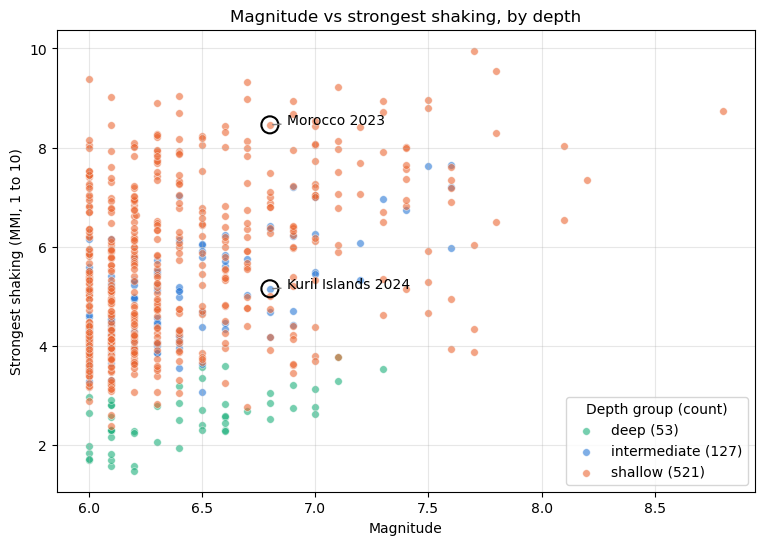

In [14]:
fig, ax = plt.subplots(figsize=(9, 6))

for group in ["deep", "intermediate", "shallow"]:
    subset = merged[merged["depth_group"] == group]
    ax.scatter(subset["mag"], subset["mmi"], s=30, alpha=0.6,
               color=depth_colors[group], edgecolor="white", linewidth=0.5,
               label=f"{group} ({len(subset)})")

# Label our two examples from Part 1
for _, row in examples.iterrows():
    ax.scatter(row["mag"], row["mmi"], s=150, facecolor="none", edgecolor="black", linewidth=1.5)
    name = "Morocco 2023" if "Morocco" in row["place"] else "Kuril Islands 2024"
    ax.annotate(name, (row["mag"], row["mmi"]), xytext=(12, 0),
                textcoords="offset points", fontsize=10,
                arrowprops=dict(arrowstyle="-", color="gray"))

ax.set_xlabel("Magnitude")
ax.set_ylabel("Strongest shaking (MMI, 1 to 10)")
ax.set_title("Magnitude vs strongest shaking, by depth")
ax.legend(title="Depth group (count)")
ax.grid(alpha=0.3)
plt.show()

**What it shows:** shaking goes up with magnitude, but depth makes a big difference. The deep earthquakes (green) sit at the bottom of the chart, mostly below MMI 4, even when they are big. The shallow ones (orange) are spread much higher. Most earthquakes in the data are shallow. Our two 6.8 examples show the gap clearly: same spot on the x axis, but Morocco (shallow) reached about MMI 8.5 while the Kuril Islands (intermediate depth) reached about 5.2. This tells us depth should be a feature in our Question 1 model.

To put a number on this, we check the correlation of each feature with shaking (Module 7). A value near 1 or minus 1 means a strong straight line relationship, and near 0 means a weak one.

In [15]:
merged[["mmi", "mag", "depth_km"]].corr().round(2)

,mmi,mag,depth_km
mmi,1.00,0.36,-0.50
mag,0.36,1.00,0.03
depth_km,-0.50,0.03,1.00


We expect magnitude to have a positive correlation with MMI (bigger, more shaking) and depth to have a negative one (deeper, less shaking). Correlation only measures straight line patterns, and depth seems to matter most as a jump between groups, so the real effect of depth may be bigger than this number shows.

### Chart 2: Warning rate by size and depth

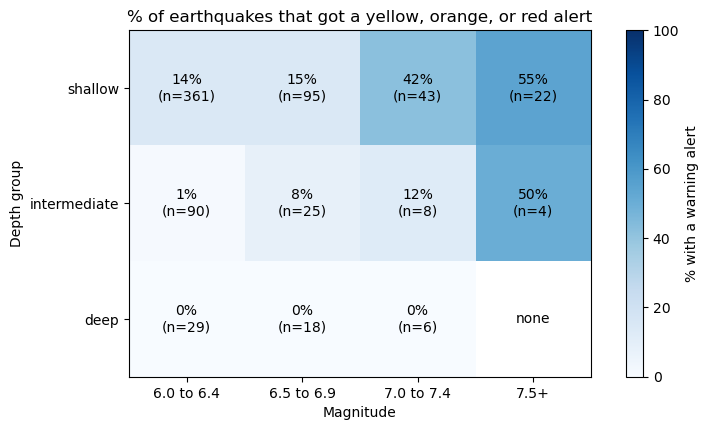

In [16]:
merged["mag_bin"] = pd.cut(merged["mag"], bins=[6, 6.5, 7, 7.5, 10], right=False,
                           labels=["6.0 to 6.4", "6.5 to 6.9", "7.0 to 7.4", "7.5+"])

rate = merged.pivot_table(index="depth_group", columns="mag_bin", values="warning",
                          aggfunc="mean", observed=False) * 100
count = merged.pivot_table(index="depth_group", columns="mag_bin", values="warning",
                           aggfunc="count", observed=False)

fig, ax = plt.subplots(figsize=(9, 4.5))
image = ax.imshow(rate.values, cmap="Blues", vmin=0, vmax=100)

ax.set_xticks(range(len(rate.columns)))
ax.set_xticklabels(rate.columns)
ax.set_yticks(range(len(rate.index)))
ax.set_yticklabels(rate.index)

# Write the % and the number of earthquakes in each box
for i in range(rate.shape[0]):
    for j in range(rate.shape[1]):
        n = count.values[i, j]
        if n == 0:
            text = "none"
        else:
            text = f"{rate.values[i, j]:.0f}%\n(n={n})"
        text_color = "white" if rate.values[i, j] > 55 else "black"
        ax.text(j, i, text, ha="center", va="center", fontsize=10, color=text_color)

ax.set_xlabel("Magnitude")
ax.set_ylabel("Depth group")
ax.set_title("% of earthquakes that got a yellow, orange, or red alert")
plt.colorbar(image, label="% with a warning alert")
plt.show()

**What it shows:** each box is the share of earthquakes in that group that got a warning. Darker means more warnings, and `n` is how many earthquakes are in the box.

* **Deep earthquakes never got a warning** in our data, at any size.
* **For shallow earthquakes, size matters a lot.** About 1 in 7 shallow earthquakes between 6.0 and 6.9 got a warning (14 to 15%), but that rises to 42% for 7.0 to 7.4 and 55% for 7.5 and up. The 7.5+ box only has 22 earthquakes, so that last number is less certain.
* **Intermediate earthquakes are in between,** but the boxes for bigger magnitudes have very few earthquakes (some have fewer than 10), so we should not read too much into them.

So size and depth together already separate a lot of the warnings, but even the riskiest group is far from 100%. That gap is what the country data is meant to help explain.

### Chart 3: Where the earthquakes happened

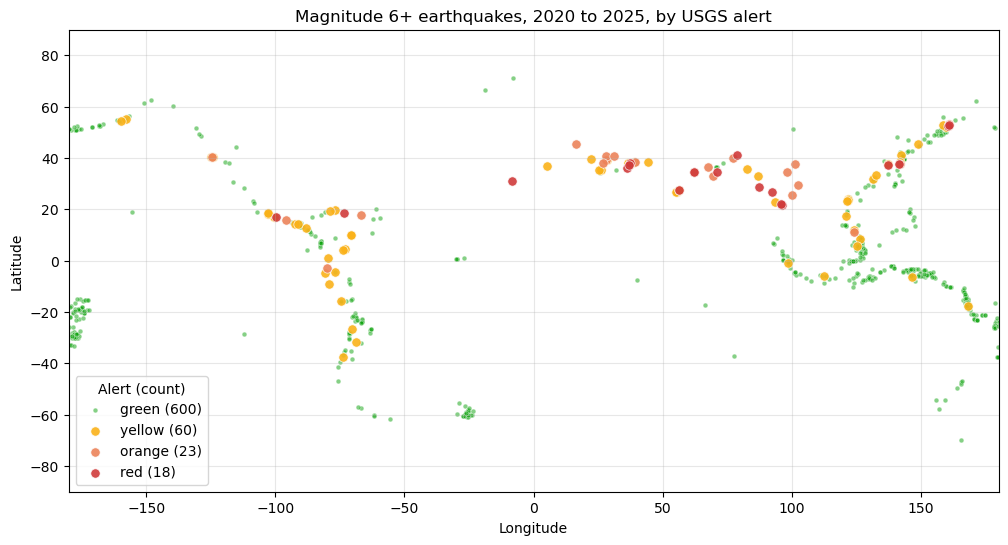

In [17]:
fig, ax = plt.subplots(figsize=(12, 6))

# Green alerts first, small and light, so the warnings stand out on top
for alert in ["green", "yellow", "orange", "red"]:
    subset = merged[merged["alert"] == alert]
    size = 12 if alert == "green" else 45
    ax.scatter(subset["longitude"], subset["latitude"], s=size,
               color=alert_colors[alert], alpha=0.5 if alert == "green" else 0.9,
               edgecolor="white", linewidth=0.5, label=f"{alert} ({len(subset)})")

ax.set_xlim(-180, 180)
ax.set_ylim(-90, 90)
ax.set_xlabel("Longitude")
ax.set_ylabel("Latitude")
ax.set_title("Magnitude 6+ earthquakes, 2020 to 2025, by USGS alert")
ax.legend(title="Alert (count)", loc="lower left")
ax.grid(alpha=0.3)
plt.show()

**What it shows:** the earthquakes trace the edges of the tectonic plates, mostly around the Pacific (the "Ring of Fire"). Many of the green alerts are out at sea, for example near Tonga and Fiji on the far left, near the South Sandwich Islands at the bottom, and along the ridges in the middle of the oceans. The warnings sit where the plate edges cross land with lots of people: the band from the Mediterranean and Turkey through Iran, Afghanistan, and the Himalayas to Myanmar, plus the west coast of Central and South America, the Philippines, and Japan. This is why we added the World Bank data: the earthquake itself is only half the story.

### Chart 4: How crowded is the country, green vs warning?

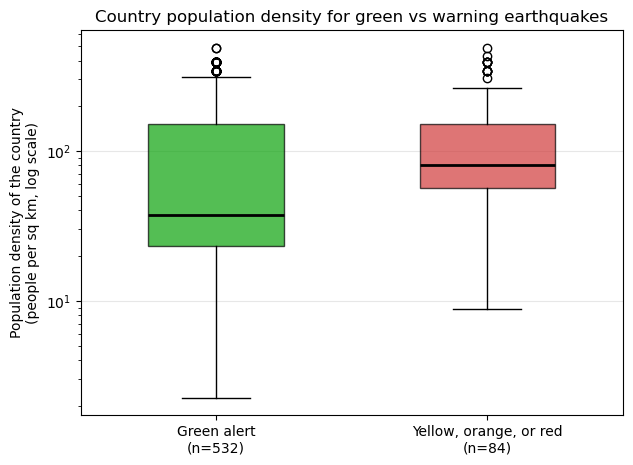

Median density, green:   37.2
Median density, warning: 80.7


In [18]:
on_land = merged.dropna(subset=["pop_density"])

green_density = on_land.loc[on_land["warning"] == 0, "pop_density"]
warning_density = on_land.loc[on_land["warning"] == 1, "pop_density"]

fig, ax = plt.subplots(figsize=(7, 5))
box = ax.boxplot([green_density, warning_density], patch_artist=True, widths=0.5,
                 medianprops=dict(color="black", linewidth=2))

box["boxes"][0].set_facecolor(alert_colors["green"])
box["boxes"][1].set_facecolor(alert_colors["red"])
for b in box["boxes"]:
    b.set_alpha(0.7)

ax.set_xticks([1, 2])
ax.set_xticklabels([f"Green alert\n(n={len(green_density)})",
                    f"Yellow, orange, or red\n(n={len(warning_density)})"])
ax.set_yscale("log")
ax.set_ylabel("Population density of the country\n(people per sq km, log scale)")
ax.set_title("Country population density for green vs warning earthquakes")
ax.grid(axis="y", alpha=0.3)
plt.show()

print("Median density, green:  ", round(green_density.median(), 1))
print("Median density, warning:", round(warning_density.median(), 1))

**What it shows:** this compares how crowded the hit country is for green earthquakes and warning earthquakes. We use a log scale because some countries are hundreds of times more crowded than others. The warning box sits higher: the median country for a warning earthquake has about twice as many people per sq km as the median country for a green one. The green box is also much wider, because it includes many earthquakes in empty places like remote islands. This supports adding country data to our Question 2 model. One limit: this is the density of the whole country, not the exact area that shook.

To check that this difference is not just random, we run a two sample t-test (Module 7) on the log of population density, since the raw values are very skewed. Our null hypothesis is that green and warning earthquakes hit countries with the same average density.

In [19]:
from scipy import stats

t_stat, p_value = stats.ttest_ind(np.log10(warning_density), np.log10(green_density),
                                  equal_var=False)
print("t statistic:", round(t_stat, 2))
print("p value:", round(p_value, 4))

if p_value < 0.05:
    print("p < 0.05, so we reject the null hypothesis: the difference is statistically significant.")
else:
    print("p >= 0.05, so we cannot reject the null hypothesis.")

t statistic: 3.19
p value: 0.0018
p < 0.05, so we reject the null hypothesis: the difference is statistically significant.


## Part 4: Functions to Check a Model

We have not picked our final models yet, but we know what kind of problems we have:

* **Question 1** predicts a number (MMI), so it is a **regression** problem.
* **Question 2** predicts green vs warning, so it is a **classification** problem.

Below are three functions we will use to check any model we try. They only need the true values and the model's predictions, so they will work with linear regression, k nearest neighbors, a decision tree, or anything else.

### Function 1: `regression_scores`

This gives three numbers that tell us how close our shaking predictions are:

* **MAE (mean absolute error):** on average, how many MMI points our prediction is off by. Easy to explain: "our model is usually off by about X."
* **RMSE (root mean squared error):** like MAE, but big misses count more. If RMSE is much bigger than MAE, the model has a few really bad misses.
* **R²:** how much of the up and down in shaking the model explains. 1 is perfect, and 0 is no better than always guessing the average.

**Why it is useful:** these let us compare models on the same scale, and R² directly answers Question 1: "how much of the shaking can magnitude and depth explain?"

In [20]:
def regression_scores(y_true, y_pred):
    '''Return MAE, RMSE, and R squared for a regression model.'''
    y_true = np.array(y_true)
    y_pred = np.array(y_pred)
    errors = y_true - y_pred

    mae = np.mean(np.abs(errors))
    rmse = np.sqrt(np.mean(errors ** 2))
    r2 = 1 - np.sum(errors ** 2) / np.sum((y_true - y_true.mean()) ** 2)

    return {"MAE": round(float(mae), 3), "RMSE": round(float(rmse), 3), "R2": round(float(r2), 3)}

### Function 2: `plot_residuals`

A residual is the true value minus the prediction. This function makes two plots:

* **Predicted vs actual:** if the model is good, the dots sit close to the diagonal line.
* **Residuals vs predicted:** the dots should look like a random cloud around 0. If they form a curve or a funnel, the model is missing a pattern.

**Why it is useful:** a single score like R² can hide problems. For example, a straight line model might do fine for medium earthquakes but always guess too low for the biggest ones. That kind of pattern only shows up in a picture.

In [21]:
def plot_residuals(y_true, y_pred, title="Model check"):
    '''Plot predicted vs actual, and residuals vs predicted.'''
    y_true = np.array(y_true)
    y_pred = np.array(y_pred)
    residuals = y_true - y_pred

    fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))

    axes[0].scatter(y_pred, y_true, alpha=0.5, s=20, color="#2a78d6")
    low = min(y_true.min(), y_pred.min())
    high = max(y_true.max(), y_pred.max())
    axes[0].plot([low, high], [low, high], color="gray", linestyle="--")
    axes[0].set_xlabel("Predicted")
    axes[0].set_ylabel("Actual")
    axes[0].set_title("Predicted vs actual")

    axes[1].scatter(y_pred, residuals, alpha=0.5, s=20, color="#2a78d6")
    axes[1].axhline(0, color="gray", linestyle="--")
    axes[1].set_xlabel("Predicted")
    axes[1].set_ylabel("Residual (actual minus predicted)")
    axes[1].set_title("Residuals")

    fig.suptitle(title)
    plt.tight_layout()
    plt.show()

### Function 3: `classification_scores`

This builds a confusion matrix (how many greens and warnings the model got right and wrong) and works out:

* **Accuracy:** share of all earthquakes it got right.
* **Precision:** when the model says "warning," how often it is right.
* **Recall:** out of all the real warnings, how many the model caught.
* **F1:** one number that balances precision and recall.

**Why it is useful:** our data is unbalanced. Most earthquakes are green (well over 80%, see the share printed in Step 2), so a lazy model that always says "green" would already be very accurate while catching zero warnings. Accuracy alone would fool us. Recall matters most here, because missing a real warning is the worst mistake an earthquake model can make.

In [22]:
def classification_scores(y_true, y_pred):
    '''Return a confusion matrix and the main scores for green (0) vs warning (1).'''
    y_true = np.array(y_true)
    y_pred = np.array(y_pred)

    tp = np.sum((y_true == 1) & (y_pred == 1))   # warning, caught
    fn = np.sum((y_true == 1) & (y_pred == 0))   # warning, missed
    fp = np.sum((y_true == 0) & (y_pred == 1))   # false alarm
    tn = np.sum((y_true == 0) & (y_pred == 0))   # green, correct

    matrix = pd.DataFrame([[tn, fp], [fn, tp]],
                          index=["Actual green", "Actual warning"],
                          columns=["Predicted green", "Predicted warning"])

    accuracy = (tp + tn) / len(y_true)
    precision = tp / (tp + fp) if (tp + fp) > 0 else 0
    recall = tp / (tp + fn) if (tp + fn) > 0 else 0
    f1 = 2 * precision * recall / (precision + recall) if (precision + recall) > 0 else 0

    scores = {"Accuracy": round(float(accuracy), 3), "Precision": round(float(precision), 3),
              "Recall": round(float(recall), 3), "F1": round(float(f1), 3)}
    return matrix, scores

### Testing the functions

To make sure the functions work, we test them on very simple "models." These are not our final models. They are baselines, the scores any real model has to beat.

**Question 1 baselines:**
* Always guess the average MMI (this should give R² of 0).
* A straight line using only magnitude, fit with `np.polyfit`.

In [23]:
y = merged["mmi"]

guess_average = np.full(len(y), y.mean())
print("Always guess the average:", regression_scores(y, guess_average))

slope, intercept = np.polyfit(merged["mag"], y, 1)
line_guess = slope * merged["mag"] + intercept
print("Straight line on magnitude:", regression_scores(y, line_guess))

Always guess the average: {'MAE': 1.362, 'RMSE': 1.645, 'R2': 0.0}
Straight line on magnitude: {'MAE': 1.233, 'RMSE': 1.534, 'R2': 0.13}


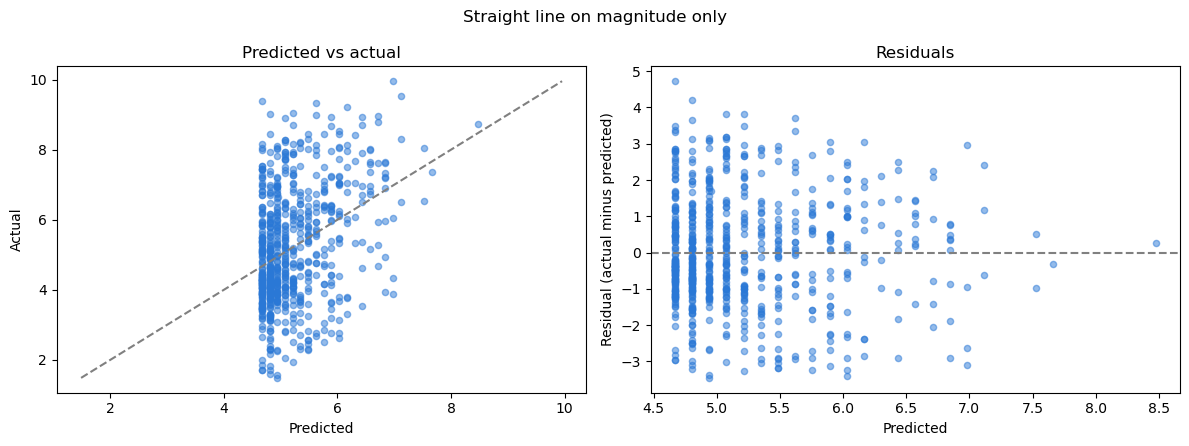

In [24]:
plot_residuals(y, line_guess, title="Straight line on magnitude only")

If the residual plot shows that the shallow earthquakes are mostly above 0 (the line guessed too low) and the deep ones mostly below 0, that is a sign depth is missing from the model, which is exactly what we plan to add.

**Question 2 baselines:**
* Always say "green."
* A simple rule: say "warning" if the shaking is MMI 6.5 or higher.

In [25]:
y_warning = merged["warning"]

always_green = np.zeros(len(y_warning))
matrix, scores = classification_scores(y_warning, always_green)
print("Always say green:", scores)
matrix

Always say green: {'Accuracy': 0.856, 'Precision': 0.0, 'Recall': 0.0, 'F1': 0.0}


,Predicted green,Predicted warning
Actual green,600,0
Actual warning,101,0


In [26]:
mmi_rule = (merged["mmi"] >= 6.5).astype(int)
matrix, scores = classification_scores(y_warning, mmi_rule)
print("Warning if MMI >= 6.5:", scores)
matrix

Warning if MMI >= 6.5: {'Accuracy': 0.893, 'Precision': 0.582, 'Recall': 0.911, 'F1': 0.71}


,Predicted green,Predicted warning
Actual green,534,66
Actual warning,9,92


The "always green" baseline shows why we need more than accuracy: it scores high on accuracy but has a recall of 0. The MMI rule shows that the functions can tell a useful rule apart from a useless one. Our real models in Phase III will need to beat both.

## Part 5: Ethical Considerations

**1. The data is not equal across the world.** The `felt` column comes from people sending reports online. Places with more internet access and people who know about the USGS website send more reports, so a high `felt` count can mean "rich and connected," not just "strong shaking." Seismic stations are also spread unevenly, so shaking estimates in some poorer regions are less precise. If our model leans on these columns, it could work better for wealthy countries than for the places that need it most.

**2. We are predicting a prediction.** The USGS alert is itself the output of a model (PAGER) that estimates deaths and losses. If our model learns to copy PAGER, it also copies any mistakes PAGER makes. We need to be clear that our project explains patterns in the alerts. It does not measure real damage.

**3. Country averages hide real people.** Population density and GDP per capita are country averages. A rich country can still have poor rural villages with weak buildings, like the area that was hit in Morocco. Using country numbers can make a place look safer than it is. We should not use our results to say anything about a single town or community.

**4. A wrong "green" can hurt people.** In this topic, missing a dangerous earthquake is far worse than a false alarm. If someone used a model like mine to decide where to send help, a missed warning could delay aid. This is why we focus on recall, and why our model should only be used for learning and research, not for real emergency decisions.

**5. Risk of unfair labels.** Results like "earthquakes in poor countries are more deadly" could be misused, for example by insurers charging more or investors avoiding a region. The real lesson is that building quality and preparation save lives, so the results should be framed around what can be improved, not around blaming places.

**6. Respect for the people affected.** Each row with a red alert is a real disaster where people died. We want to talk about these events carefully and not treat them as just data points.

**Privacy:** the data does not include any personal information. Felt reports are counted, not linked to names, so privacy risk is low.